# Week 6 — Tasks 3 and 4: differentiating JCM

Run top to bottom on the DataHub GPU. The first call for each new window length compiles (a minute or so), so every timing below uses the **second** call.

In [3]:
%pip install "jcm==3.0.0" matplotlib psutil

  Using cached jcm-3.0.0-py3-none-any.whl.metadata (1.2 kB)
  Using cached dinosaur-1.5.1-py3-none-any.whl.metadata (3.5 kB)
  Using cached flax-0.12.12-py3-none-any.whl.metadata (11 kB)
  Using cached jax-0.10.2-py3-none-any.whl.metadata (13 kB)
  Using cached jax_datetime-0.1.2-py3-none-any.whl.metadata (17 kB)
  Using cached tree_math-0.2.1-py3-none-any.whl.metadata (477 bytes)
  Using cached hydra_core-1.3.8-py3-none-any.whl.metadata (5.7 kB)
  Using cached pytest_cov-7.1.0-py3-none-any.whl.metadata (32 kB)
  Using cached furo-2025.12.19-py3-none-any.whl.metadata (4.9 kB)
  Using cached myst_parser-5.1.0-py3-none-any.whl.metadata (5.6 kB)
  Using cached jax_solar-0.1.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached jax_rrtmgp-0.7.0-py3-none-any.whl.metadata (19 kB)
  Using cached jaxlib-0.10.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (1.3 kB)
  Using cached pint-0.26.2-py3-none-any.whl.metadata (10 kB)
  Using cached xarray_tensorstore-0.3.0-py3-none-any.whl.metadata (600 byte

In [1]:
from importlib.resources import files
import time
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
from jcm import load_states_from_xarray
from jcm.forcing import ForcingData
from jcm.model import Model
from jcm.physics.speedy.speedy_coords import get_speedy_coords
from jcm.terrain import TerrainData

print(jax.devices())   # should list a GPU

coords = get_speedy_coords(spectral_truncation=31, layers=8)
data = files("jcm") / "data/bc/t30/clim"
terrain = TerrainData.from_file(data / "terrain.nc", coords=coords)
bc = ForcingData.from_file(data / "forcing.nc", coords=coords, align_mode="wrap_year")
model = Model(coords=coords, terrain=terrain, time_step=30)

# Spin up from rest, then start every experiment from the same state
spinup = model.run(forcing=bc, total_time=60, save_interval=60).to_xarray()
ic = load_states_from_xarray(spinup.isel(time=-1).sortby("level"))

ocean = jnp.asarray(np.asarray(terrain.fmask) < 0.5)        # (lon, lat), True over ocean
w = np.cos(np.deg2rad(spinup.lat.values))
weights = jnp.broadcast_to(jnp.asarray(w / w.mean()), ocean.shape)

lon = spinup.lon.values      # if this fails, look in spinup.coords for the longitude name
lat = spinup.lat.values
zero = jnp.zeros(ocean.shape)
ones = jnp.ones_like(zero)
ocean_np, w_np = np.asarray(ocean), np.asarray(weights)
N = ocean_np.size            # total number of grid points
print("grid (lon, lat):", ocean.shape, "| ocean points:", int(ocean_np.sum()))

[CpuDevice(id=0)]


/Users/linuslee/miniforge3/lib/python3.12/site-packages/jcm/data/bc/interpolate.py:105: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  return xr.merge([ds_interp, passthrough])
/Users/linuslee/miniforge3/lib/python3.12/site-packages/jcm/data/bc/interpolate.py:53: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  return xr.merge([daily_time

grid (lon, lat): (96, 48) | ocean points: 3080


## Helpers

`make_J(ic, window)` is the handout's `global_mean_olr`, with the start state and window as arguments so task 4 is just a loop.

In [2]:
def make_J(ic, window):
    """Return J(dsst): global-mean OLR (W m-2) averaged over `window` days from state `ic`,
    with SST + dsst over the ocean."""
    def J(dsst):
        sst = bc.sea_surface_temperature
        forcing = bc.copy(sea_surface_temperature=sst.replace(values=sst.values + dsst * ocean))
        out = model.run(initial_state=ic, forcing=forcing, total_time=window,
                        save_interval=window, output_averages=True).to_xarray()
        return jnp.mean(weights * out["longwave_rad.ftop"].isel(time=-1).data)
    return J


def timed(fn, *args):
    """Call fn(*args) once to compile, then time a second call. Returns (result, seconds)."""
    jax.block_until_ready(fn(*args))
    t0 = time.perf_counter()
    result = jax.block_until_ready(fn(*args))
    return result, time.perf_counter() - t0


def central_fd(J, pattern, h):
    """Centred finite difference (J(+h*pattern) - J(-h*pattern)) / 2h."""
    return (J(h * pattern) - J(-h * pattern)) / (2 * h)


def vjp_map(J):
    """One reverse-mode pass: returns (J0, dJ/d(dsst) at every grid point)."""
    J0, backward = jax.vjp(J, zero)
    (g,) = backward(jnp.ones_like(J0))     # the same as backward(1.0)
    return J0, g


def to_local(g):
    """Remove the area weight. This is sensitivity_map / weights times the constant N, chosen
    so that the area-weighted global mean of the result equals the uniform-warming response.
    Units: W m-2 K-1. The constant does not change the pattern."""
    return np.asarray(g) / w_np * N


def plot_map(field, ax, title="", cmap="RdBu_r", symmetric=True, mask_land=True):
    f = np.asarray(field, dtype=float)
    if mask_land:
        f = np.where(ocean_np, f, np.nan)
    if symmetric:                       # diverging colours centred on zero
        v = np.nanpercentile(np.abs(f), 99)
        lims = dict(vmin=-v, vmax=v)
    else:
        lims = dict(vmin=np.nanpercentile(f, 1), vmax=np.nanpercentile(f, 99))
    m = ax.pcolormesh(lon, lat, f.T, cmap=cmap, shading="auto", **lims)
    ax.contour(lon, lat, ocean_np.T.astype(float), levels=[0.5], colors="k", linewidths=0.5)
    ax.set_title(title, fontsize=10)
    plt.colorbar(m, ax=ax, shrink=0.85)
    return m


def pattern_corr(a, b):
    """Area-weighted pattern correlation of two sensitivity maps over the ocean."""
    a, b, wt = to_local(a)[ocean_np], to_local(b)[ocean_np], w_np[ocean_np]
    a = a - np.average(a, weights=wt)
    b = b - np.average(b, weights=wt)
    return np.sum(wt * a * b) / np.sqrt(np.sum(wt * a * a) * np.sum(wt * b * b))


def gpu_bytes(key="bytes_in_use"):
    """Device memory from JAX's own allocator, in bytes (NaN on CPU).
    nvidia-smi is no use here: JAX preallocates most of the GPU at start-up."""
    stats = jax.devices()[0].memory_stats()
    return stats.get(key, np.nan) if stats else np.nan

## Task 3.1 — Forward mode vs finite differences (6-hour window)

If FD(1 K) and FD(0.1 K) roughly agree with each other but both differ from the jvp, suspect on/off switches (the number of columns crossing a threshold scales with h, so the FD stays put as h shrinks). If FD moves a lot between 1 K and 0.1 K, suspect ordinary nonlinearity (a centred FD's error shrinks like h²). The 0.01 K row is extra: it shows float32 round-off starting to creep in, as in task 1.

In [3]:
WINDOW = 0.25  # days (6 hours)
J = make_J(ic, WINDOW)

(J0, dJ_uniform), t_jvp = timed(lambda: jax.jvp(J, (zero,), (ones,)))
print(f"J0 = {float(J0):.3f} W m-2")
print(f"jvp:          dJ/dSST for uniform ocean warming = {float(dJ_uniform):+.5f} W m-2 K-1")

for h in [1.0, 0.1, 0.01]:
    fd = float(central_fd(J, ones, h))
    print(f"FD h = {h:<4} K: {fd:+.5f} W m-2 K-1   (FD / jvp = {fd / float(dJ_uniform):.3f})")

J0 = 234.680 W m-2
jvp:          dJ/dSST for uniform ocean warming = +0.39534 W m-2 K-1
FD h = 1.0  K: +0.34757 W m-2 K-1   (FD / jvp = 0.879)
FD h = 0.1  K: +0.31548 W m-2 K-1   (FD / jvp = 0.798)
FD h = 0.01 K: -0.14267 W m-2 K-1   (FD / jvp = -0.361)


## Task 3.2 — Reverse mode: the sensitivity map

Top panel: `sensitivity_map` as returned (includes the cos(lat) area weight, so high latitudes look small). Bottom: per unit area.

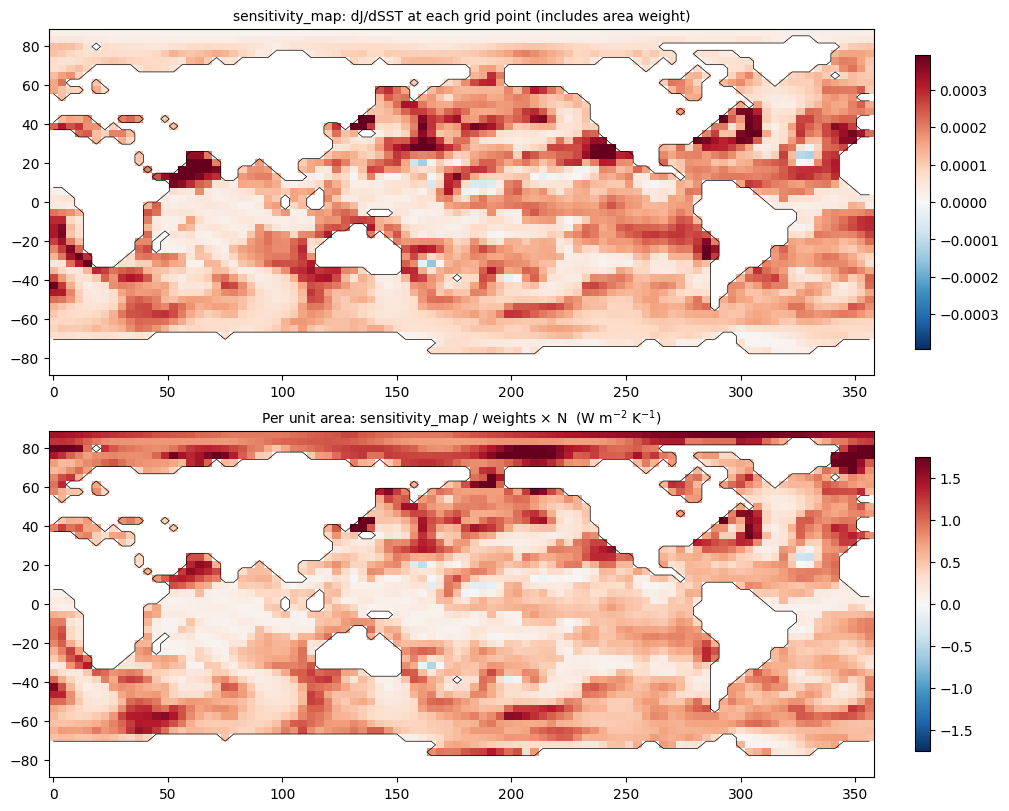

In [4]:
(_, sensitivity_map), t_vjp = timed(vjp_map, J)

fig, axs = plt.subplots(2, 1, figsize=(10, 8), constrained_layout=True)
plot_map(sensitivity_map, axs[0], "sensitivity_map: dJ/dSST at each grid point (includes area weight)")
plot_map(to_local(sensitivity_map), axs[1], "Per unit area: sensitivity_map / weights × N  (W m$^{-2}$ K$^{-1}$)")
plt.show()

To explain *where* the sensitivity is large, compare it with the state of the atmosphere above each point during the same 6 hours.

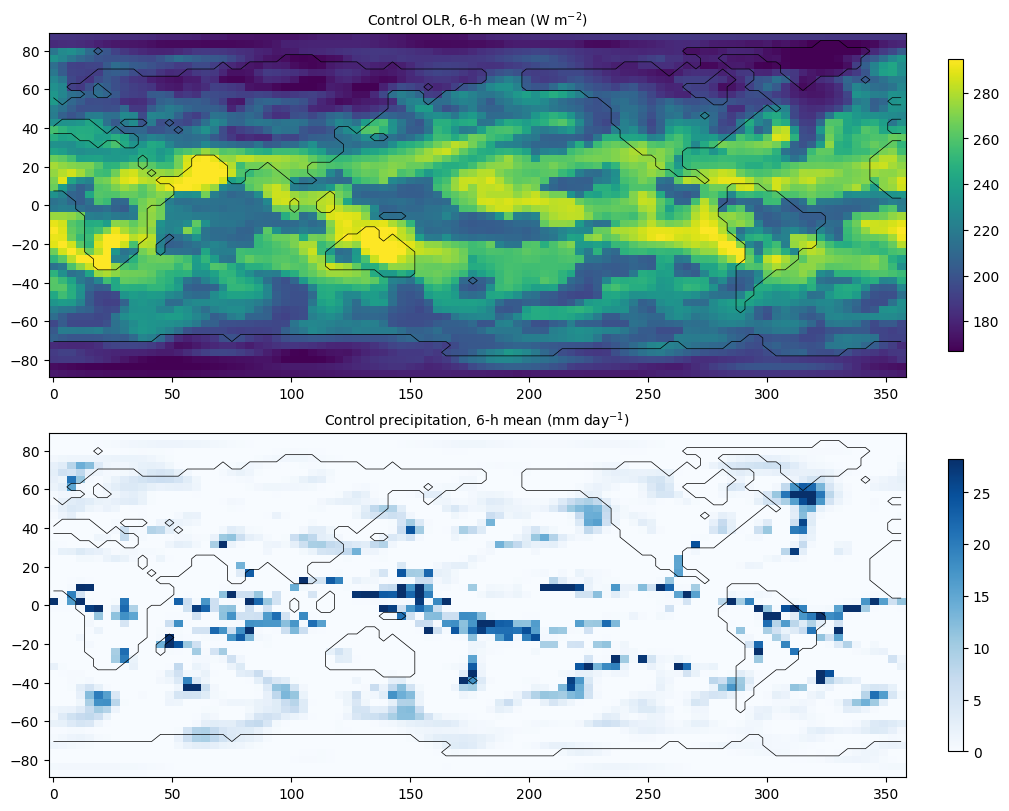

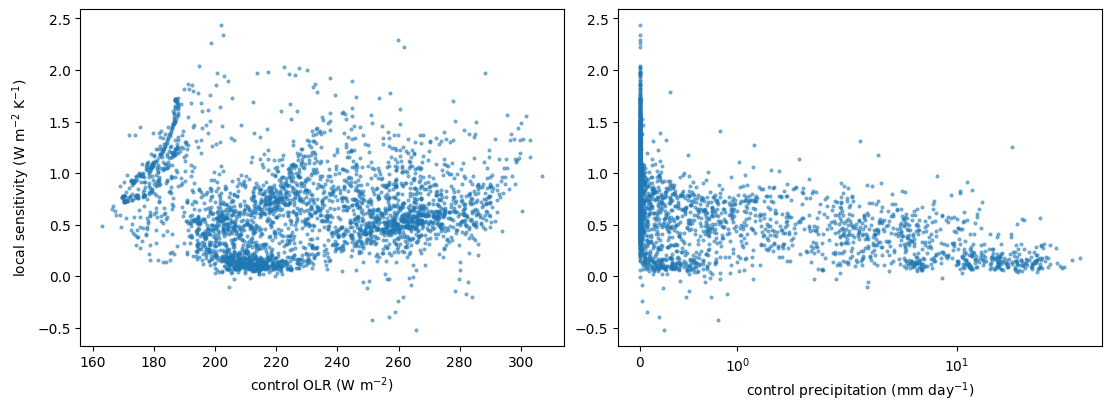

Other diagnostics to compare with (cloud cover, humidity, ...):
['condensation.dqlsc', 'condensation.dtlsc', 'condensation.precls', 'convection.cbmf', 'convection.precnv', 'convection.qdif', 'convection.se', 'geopotential', 'humidity.qsat', 'humidity.rh', 'land_model.stl_lm', 'longwave_rad.dfabs', 'longwave_rad.ftop', 'mod_radcon.ablco2', 'mod_radcon.alb_l', 'mod_radcon.alb_s', 'mod_radcon.albsfc', 'mod_radcon.flux.0', 'mod_radcon.flux.1', 'mod_radcon.flux.2', 'mod_radcon.flux.3', 'mod_radcon.snowc', 'mod_radcon.st4a.0', 'mod_radcon.st4a.1', 'mod_radcon.stratc.0', 'mod_radcon.stratc.1', 'mod_radcon.tau2.0', 'mod_radcon.tau2.1', 'mod_radcon.tau2.2', 'mod_radcon.tau2.3', 'normalized_surface_pressure', 'shortwave_rad.cloudc', 'shortwave_rad.cloudstr', 'shortwave_rad.dfabs', 'shortwave_rad.fsol', 'shortwave_rad.ftop', 'shortwave_rad.gse', 'shortwave_rad.heating_rate', 'shortwave_rad.ozone', 'shortwave_rad.ozupp', 'shortwave_rad.qcloud', 'shortwave_rad.rsds', 'shortwave_rad.rsns', 'shortwav

In [5]:
ctrl = model.run(initial_state=ic, forcing=bc, total_time=WINDOW,
                 save_interval=WINDOW, output_averages=True).to_xarray()
olr0 = np.asarray(ctrl["longwave_rad.ftop"].isel(time=-1).data)
precip0 = np.asarray(ctrl["surface_exchange.precipitation"].isel(time=-1).data) * 86400   # mm/day

fig, axs = plt.subplots(2, 1, figsize=(10, 8), constrained_layout=True)
plot_map(olr0, axs[0], "Control OLR, 6-h mean (W m$^{-2}$)", cmap="viridis", symmetric=False, mask_land=False)
plot_map(precip0, axs[1], "Control precipitation, 6-h mean (mm day$^{-1}$)", cmap="Blues", symmetric=False, mask_land=False)
plt.show()

loc = to_local(sensitivity_map)[ocean_np]
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axs[0].scatter(olr0[ocean_np], loc, s=4, alpha=0.5)
axs[0].set(xlabel="control OLR (W m$^{-2}$)", ylabel="local sensitivity (W m$^{-2}$ K$^{-1}$)")
axs[1].scatter(precip0[ocean_np], loc, s=4, alpha=0.5)
axs[1].set(xlabel="control precipitation (mm day$^{-1}$)", xscale="symlog")
plt.show()

print("Other diagnostics to compare with (cloud cover, humidity, ...):")
print(sorted(ctrl.data_vars))

## Task 3.3 — Dot-product test

`sum(map × pattern)` (reverse mode) should equal `jvp` with that pattern (forward mode) to float32 rounding, roughly 1e-6 to 1e-5 relative. Niño-3.4 is 5°S–5°N, 170°W–120°W, which is 190–240°E.

In [6]:
lon360 = np.mod(lon, 360)
LON, LAT = np.meshgrid(lon360, lat, indexing="ij")          # (lon, lat), same layout as `ocean`
nino34 = jnp.asarray(((np.abs(LAT) <= 5) & (LON >= 190) & (LON <= 240)).astype(np.float32))
print("Niño-3.4 box:", int(nino34.sum()), "grid points,", int((nino34 * ocean).sum()), "over ocean")

for name, pattern in [("uniform", ones), ("Niño-3.4", nino34)]:
    adjoint = float(jnp.sum(sensitivity_map * pattern))     # reverse mode: map · pattern
    _, tangent = jax.jvp(J, (zero,), (pattern,))            # forward mode
    tangent = float(tangent)
    rel = abs(adjoint - tangent) / abs(tangent)
    print(f"{name:9s} map·pattern = {adjoint:+.6e}   jvp = {tangent:+.6e}   relative difference = {rel:.1e}")

print(f"Niño-3.4 finite difference (h = 1 K): {float(central_fd(J, nino34, 1.0)):+.6e}")

Niño-3.4 box: 28 grid points, 28 over ocean
uniform   map·pattern = +3.953401e-01   jvp = +3.953419e-01   relative difference = 4.7e-06
Niño-3.4  map·pattern = +4.799089e-03   jvp = +4.799121e-03   relative difference = 6.7e-06
Niño-3.4 finite difference (h = 1 K): +6.988525e-03


## Task 3.4 — Cost

In [7]:
_, t_run = timed(J, zero)
n_ocean = int(ocean_np.sum())

def fmt(seconds):
    return f"{seconds / 60:.0f} min ({seconds / 3600:.1f} h)"

print(f"one 6-h model run: {t_run:.2f} s | jvp: {t_jvp:.2f} s | vjp + backward: {t_vjp:.2f} s")
print(f"FD map, one-sided ({n_ocean + 1} runs): {fmt((n_ocean + 1) * t_run)}")
print(f"FD map, centred   ({2 * n_ocean} runs): {fmt(2 * n_ocean * t_run)}")
print(f"forward mode, one jvp per point ({n_ocean} jvps): {fmt(n_ocean * t_jvp)}")

one 6-h model run: 0.16 s | jvp: 0.29 s | vjp + backward: 0.43 s
FD map, one-sided (3081 runs): 8 min (0.1 h)
FD map, centred   (6160 runs): 17 min (0.3 h)
forward mode, one jvp per point (3080 jvps): 15 min (0.2 h)


## Task 4 — How long can the window be?

Windows run in ascending order, so the peak-memory high-water mark means something. "stored" is the memory held by the saved forward run, measured while the `backward` function is still alive. If the 4-day reverse pass runs out of GPU memory, the loop reports it and carries on: that is a result worth reporting, not just an error.

In [8]:
def run_window(ic, window):
    """Tasks 3.1-3.2 at one window length, plus timings and memory."""
    Jw = make_J(ic, window)
    r = {}
    _, r["t_run"] = timed(Jw, zero)
    (_, dJ), r["t_jvp"] = timed(lambda: jax.jvp(Jw, (zero,), (ones,)))
    r["dJ"] = float(dJ)
    r["fd1"] = float(central_fd(Jw, ones, 1.0))
    r["fd01"] = float(central_fd(Jw, ones, 0.1))
    (_, g), r["t_vjp"] = timed(vjp_map, Jw)        # also compiles the reverse pass
    r["map"], r["norm"] = np.asarray(g), float(jnp.linalg.norm(g))

    J0w, backward = jax.vjp(Jw, zero)              # `backward` holds the stored forward run
    stored = sum(x.nbytes for x in jax.tree_util.tree_leaves(backward) if hasattr(x, "nbytes"))
    r["stored_GB"] = stored / 1e9
    del backward
    r["peak_GB"] = gpu_bytes("peak_bytes_in_use") / 1e9
    return r


WINDOWS = [0.25, 1, 2, 4]   # days
results = {}
for win in WINDOWS:
    try:
        results[win] = r = run_window(ic, win)
    except Exception as e:  # e.g. RESOURCE_EXHAUSTED when the GPU runs out of memory
        print(f"{win} d failed: {type(e).__name__}: {str(e)[:300]}")
        continue
    print(f"{win:>5} d | jvp {r['dJ']:+.4f}  FD(1 K) {r['fd1']:+.4f}  FD(0.1 K) {r['fd01']:+.4f} | "
          f"|map| {r['norm']:.3e} | run {r['t_run']:.1f} s  jvp {r['t_jvp']:.1f} s  vjp {r['t_vjp']:.1f} s | "
          f"stored {r['stored_GB']:.2f} GB  peak {r['peak_GB']:.2f} GB")

 0.25 d | jvp +0.3953  FD(1 K) +0.3476  FD(0.1 K) +0.3155 | |map| 8.614e-03 | run 0.2 s  jvp 0.3 s  vjp 0.4 s | stored nan GB  peak nan GB
    1 d | jvp +0.4753  FD(1 K) +0.2115  FD(0.1 K) +0.3429 | |map| 1.158e-02 | run 0.5 s  jvp 0.9 s  vjp 1.5 s | stored nan GB  peak nan GB
    2 d | jvp +0.6198  FD(1 K) +0.2324  FD(0.1 K) +0.3304 | |map| 1.916e-02 | run 0.9 s  jvp 1.8 s  vjp 3.0 s | stored nan GB  peak nan GB
    4 d | jvp +0.8775  FD(1 K) +0.3713  FD(0.1 K) +0.4937 | |map| 3.429e-02 | run 1.9 s  jvp 3.8 s  vjp 6.0 s | stored nan GB  peak nan GB


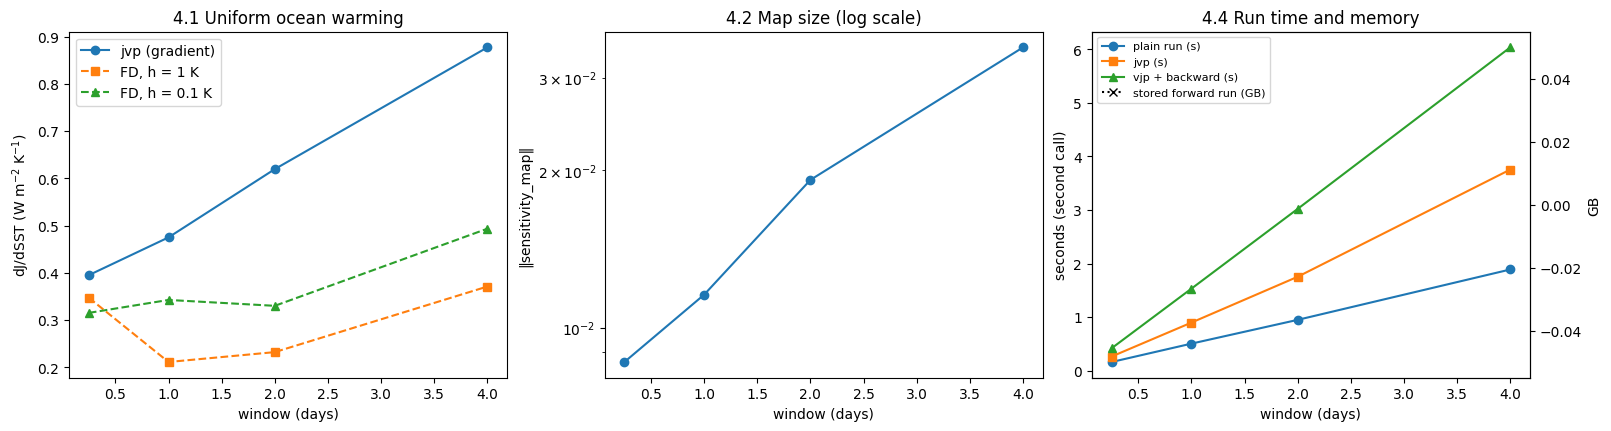

‖map‖ grows roughly like exp(0.37 × days), an e-folding time of about 2.7 days


In [9]:
wins = list(results)
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True)

axs[0].plot(wins, [results[w]["dJ"] for w in wins], "o-", label="jvp (gradient)")
axs[0].plot(wins, [results[w]["fd1"] for w in wins], "s--", label="FD, h = 1 K")
axs[0].plot(wins, [results[w]["fd01"] for w in wins], "^--", label="FD, h = 0.1 K")
axs[0].set(xlabel="window (days)", ylabel="dJ/dSST (W m$^{-2}$ K$^{-1}$)", title="4.1 Uniform ocean warming")
axs[0].legend()

axs[1].semilogy(wins, [results[w]["norm"] for w in wins], "o-")
axs[1].set(xlabel="window (days)", ylabel="‖sensitivity_map‖", title="4.2 Map size (log scale)")

axs[2].plot(wins, [results[w]["t_run"] for w in wins], "o-", label="plain run (s)")
axs[2].plot(wins, [results[w]["t_jvp"] for w in wins], "s-", label="jvp (s)")
axs[2].plot(wins, [results[w]["t_vjp"] for w in wins], "^-", label="vjp + backward (s)")
axs[2].set(xlabel="window (days)", ylabel="seconds (second call)", title="4.4 Run time and memory")
ax_mem = axs[2].twinx()
ax_mem.plot(wins, [results[w]["stored_GB"] for w in wins], "k:", marker="x", label="stored forward run (GB)")
ax_mem.set_ylabel("GB")
h1, l1 = axs[2].get_legend_handles_labels()
h2, l2 = ax_mem.get_legend_handles_labels()
axs[2].legend(h1 + h2, l1 + l2, fontsize=8)
plt.show()

# On a log axis, exponential growth is a straight line; its slope is a rough growth rate.
if len(wins) >= 2:
    rate = np.polyfit(np.array(wins, float), np.log([results[w]["norm"] for w in wins]), 1)[0]
    msg = f"‖map‖ grows roughly like exp({rate:.2f} × days)"
    print(msg + (f", an e-folding time of about {1 / rate:.1f} days" if rate > 0 else ""))

### Does the pattern stay recognisable?

Each panel has its own colour scale, so you are comparing patterns, not sizes.

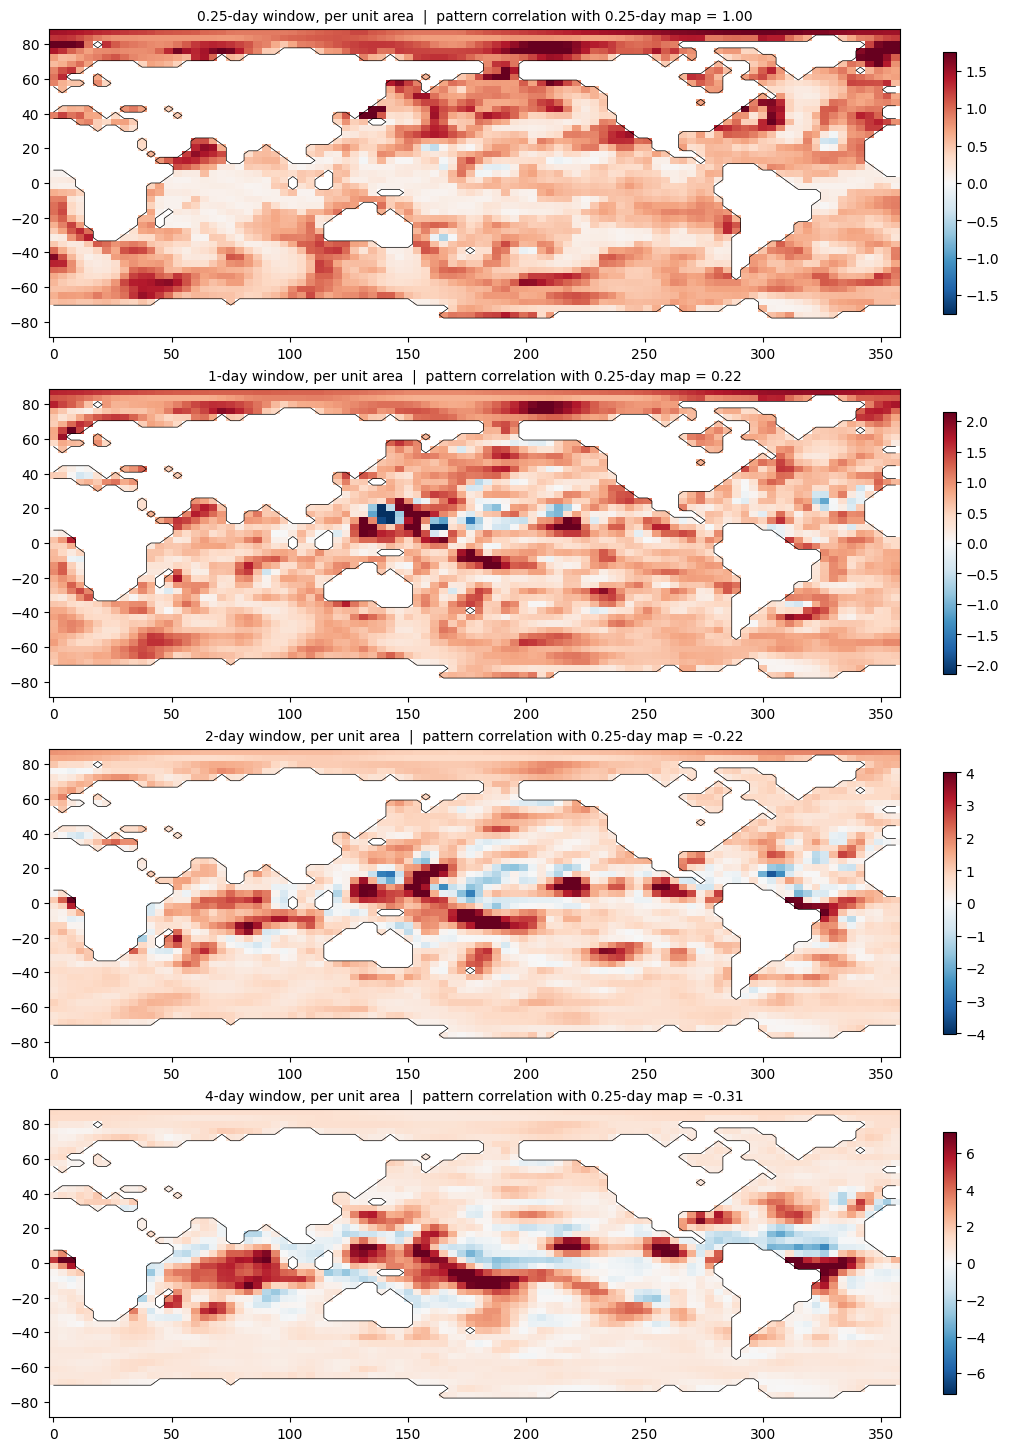

In [10]:
fig, axs = plt.subplots(len(wins), 1, figsize=(10, 3.6 * len(wins)), constrained_layout=True, squeeze=False)
for ax, w in zip(axs[:, 0], wins):
    r = pattern_corr(results[w]["map"], results[wins[0]]["map"])
    plot_map(to_local(results[w]["map"]), ax,
             f"{w}-day window, per unit area  |  pattern correlation with {wins[0]}-day map = {r:.2f}")
plt.show()

### Task 4.3 — Different starting states

One 80-day spin-up saved every 10 days gives the day-60, 70 and 80 states in a single run.

In [11]:
spin80 = model.run(forcing=bc, total_time=80, save_interval=10).to_xarray()
print(spin80.time.values)   # check that the last three outputs are days 60, 70 and 80
ics = {day: load_states_from_xarray(spin80.isel(time=i).sortby("level"))
       for day, i in [(60, -3), (70, -2), (80, -1)]}

# The day-60 state should reproduce task 3's J0 (to rounding)
print(float(make_J(ics[60], 0.25)(zero)), "vs", float(J0))

['2000-01-11T00:00:00.000' '2000-01-21T00:00:00.000'
 '2000-01-31T00:00:00.000' '2000-02-10T00:00:00.000'
 '2000-02-20T00:00:00.000' '2000-03-01T00:00:00.000'
 '2000-03-11T00:00:00.000' '2000-03-21T00:00:00.000']
234.68020629882812 vs 234.68020629882812


window | jvp dJ/dSST from each start | pattern correlation between starts
 0.25 d | +0.3953  +0.3913  +0.4068 | r(60,70) = +0.41  r(60,80) = +0.34  r(70,80) = +0.37
    1 d | +0.4753  +0.4913  +0.5063 | r(60,70) = +0.07  r(60,80) = +0.16  r(70,80) = +0.15
    2 d | +0.6198  +0.6404  +0.6525 | r(60,70) = +0.27  r(60,80) = +0.25  r(70,80) = +0.37
    4 d | +0.8775  +0.8991  +0.8825 | r(60,70) = +0.44  r(60,80) = +0.37  r(70,80) = +0.51


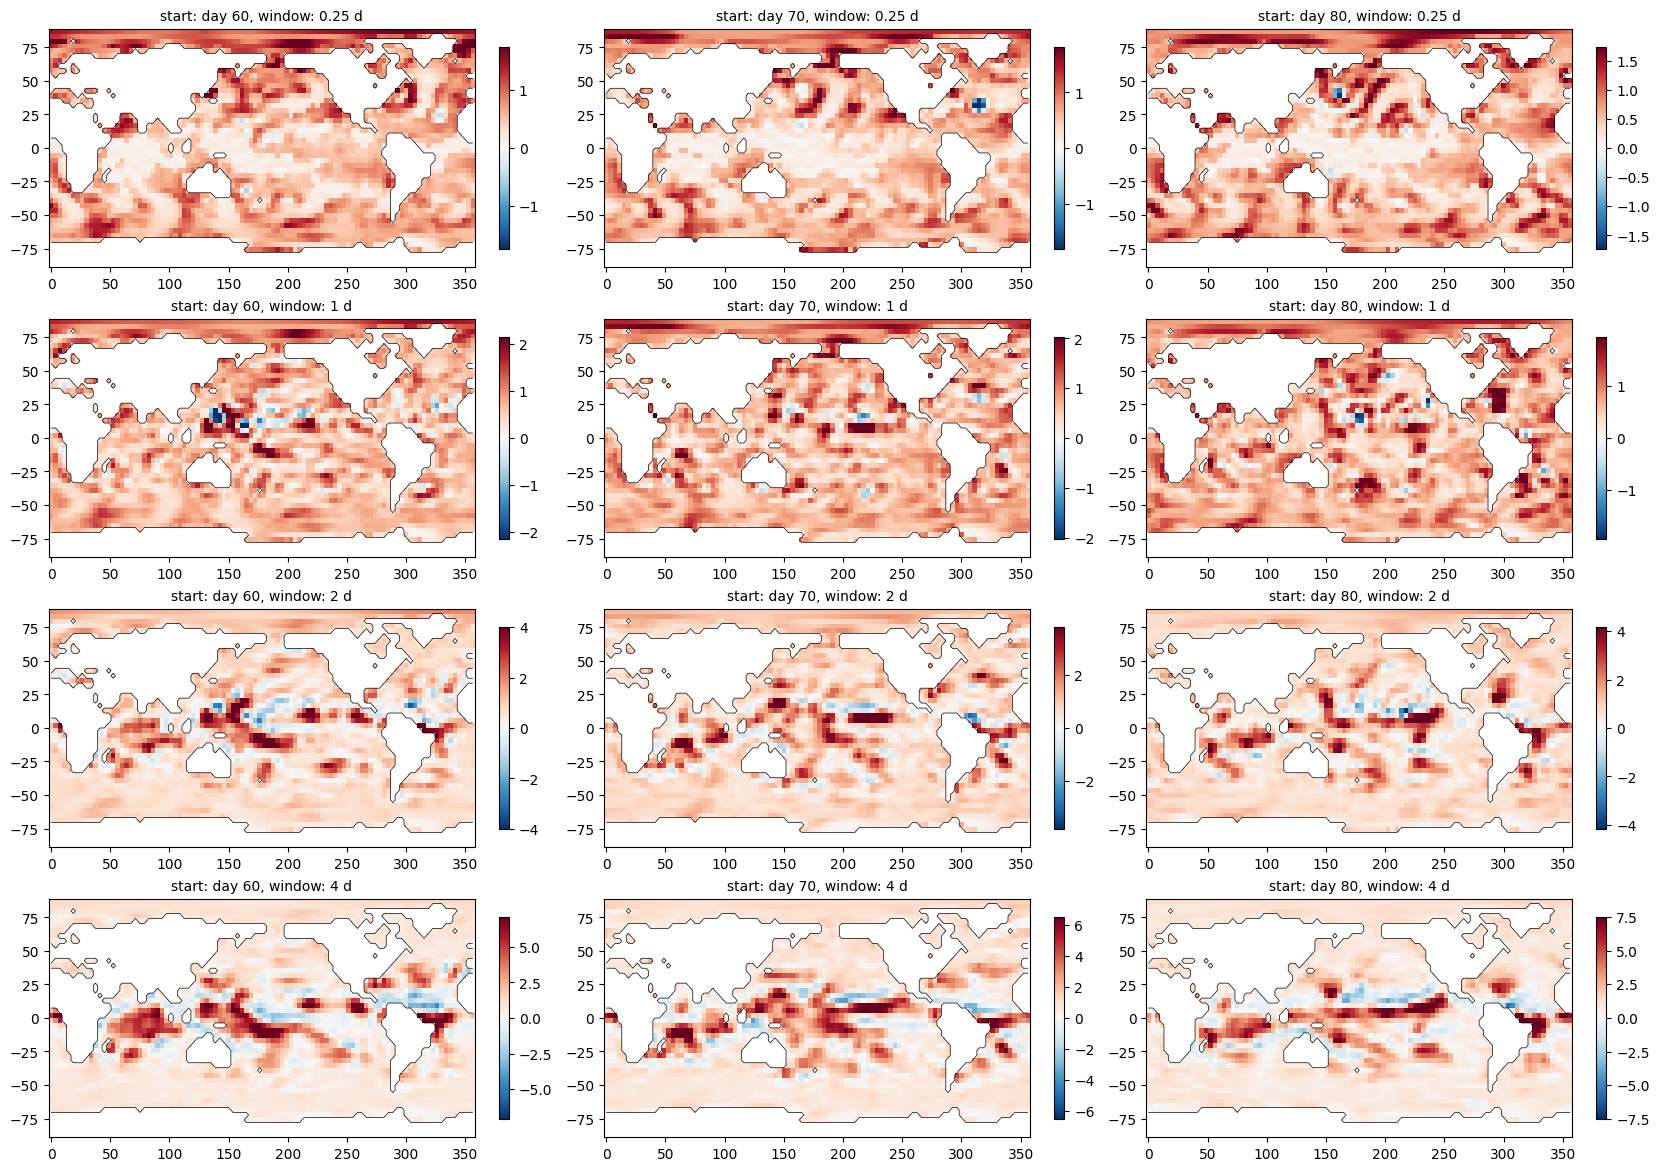

In [12]:
ic_maps, ic_dJ = {}, {}
for day, ic_d in ics.items():
    for win in wins:
        Jd = make_J(ic_d, win)
        _, g = vjp_map(Jd)
        _, dJ = jax.jvp(Jd, (zero,), (ones,))
        ic_maps[day, win], ic_dJ[day, win] = np.asarray(g), float(dJ)

days = list(ics)
pairs = [(a, b) for i, a in enumerate(days) for b in days[i + 1:]]
print("window | jvp dJ/dSST from each start | pattern correlation between starts")
for win in wins:
    dJs = "  ".join(f"{ic_dJ[d, win]:+.4f}" for d in days)
    rs = "  ".join(f"r({a},{b}) = {pattern_corr(ic_maps[a, win], ic_maps[b, win]):+.2f}" for a, b in pairs)
    print(f"{win:>5} d | {dJs} | {rs}")

fig, axs = plt.subplots(len(wins), len(days), figsize=(5.5 * len(days), 2.9 * len(wins)),
                        constrained_layout=True, squeeze=False)
for i, win in enumerate(wins):
    for j, day in enumerate(days):
        plot_map(to_local(ic_maps[day, win]), axs[i, j], f"start: day {day}, window: {win} d")
plt.show()

## Task 4: Answers

### How does `dJ_uniform` compare with the finite difference as the window grows?

The gradient and the finite difference drift further apart as the window grows. At 6 hours the finite differences are 80–88% of the gradient (jvp 0.395 W m⁻² K⁻¹; FD 0.348 for h = 1 K and 0.316 for h = 0.1 K). By 1–4 days they are only 38–72% of it.

The gradient rises steadily, from 0.395 at 6 hours to 0.878 at 4 days, and almost identically from all three starting states. The finite differences don't follow it. They stay between 0.21 and 0.49 with no clear trend. Beyond 6 hours the two step sizes also disagree with each other by 30–60%, so the finite difference is no longer a stable reference either.

At 6 hours the gap is consistent with on/off switches such as the convection trigger, which a gradient cannot see. Over longer windows, two further effects plausibly widen it. First, the +h and −h runs drift apart chaotically, which adds weather noise to the finite difference. Second, in the linearised model that the gradient follows, small perturbations keep growing, whereas in the full model they level off. The finite differences were only computed from the day-60 start, so their spread across starting states is unknown.

### How does the size of the map change with window length, and does its pattern stay recognisable?

The map's norm grows about fourfold over four days: 8.6 × 10⁻³ at 6 hours, then 1.2 × 10⁻², 1.9 × 10⁻² and 3.4 × 10⁻² at 1, 2 and 4 days. A straight-line fit on a log scale gives an e-folding time of about 2.7 days, but with four points and an uneven growth rate that figure is rough. The norm grows faster than the global response it adds up to (4× compared with 2.2×), so the sensitivity becomes concentrated in fewer, stronger features.

The pattern does not stay recognisable. Its correlation with the 6-hour map falls to 0.22 at 1 day, −0.22 at 2 days and −0.31 at 4 days. At 6 hours, the largest sensitivity per unit area is at high latitudes and in the mid-latitude storm tracks, with little in the deep tropics. By 2–4 days the high latitudes have faded and the tropical oceans dominate, with strong positive features either side of the equator and negative values along it.

One interpretation is that the 6-hour map mostly reflects extra surface emission escaping through dry, clear columns. Over several days, the tropical atmosphere's convective response to SST takes over, along with the fast growth of perturbations there.

### At which window do the maps from different starting states stop agreeing?

The three starting states are days 60, 70 and 80 of the spin-up (1, 11 and 21 March in the model calendar). The maps never agree closely grid point by grid point. Even at 6 hours, the pattern correlations between starts are only 0.34–0.41, which suggests the 6-hour map depends on where it happens to be clear or cloudy at that moment.

Agreement is worst at 1 day (0.07–0.16), so by this measure the maps have stopped agreeing by 1 day. The correlations partly recover at 2 days (0.25–0.37) and 4 days (0.37–0.51). The maps suggest this is mainly because all three concentrate their sensitivity in the same tropical belt, while the individual features sit at different longitudes.

**[Fill in: the latitude profiles correlate at __ to __, compared with __ to __ for the full maps. This (supports / does not support) the idea that the large-scale structure agrees better than the details.]**

By contrast, the global response `dJ_uniform` agrees within about 6% between starts at every window, for example 0.878–0.899 at 4 days. A single-run gradient therefore gives a robust global number over these windows, but its map depends on the weather.

### How do run time and memory grow with window length?

Run time grows linearly with window length. These are second-call timings on a MacBook CPU.

| Window | Plain run | Forward mode (jvp) | Reverse mode (vjp + backward) |
|---|---|---|---|
| 6 h | 0.16 s | 0.3 s | 0.4 s |
| 1 d | 0.5 s | 0.9 s | 1.5 s |
| 2 d | 0.9 s | 1.8 s | 3.0 s |
| 4 d | 1.9 s | 3.8 s | 6.0 s |

Forward mode costs about 2× a plain run and reverse mode about 3×, and those ratios hold at every window.

**[Fill in: the stored forward run takes __, __, __ and __ MB at 6 hours, 1, 2 and 4 days.]** This grows in proportion to the window, because reverse mode keeps every time step: 12 at 6 hours and 192 at 4 days, with 30-minute steps.

At this resolution the 4-day window ran without trouble, so cost and memory are not what limits the window here. The limit is the loss of agreement with the finite difference and between starting states.